# Credit Card Fraud Detection 
This dataset contains 10,000 credit card transactions designed to support research and experimentation in fraud detection using machine learning. The data realistically simulates both legitimate and fraudulent transactions, while maintaining a naturally imbalanced class distribution, which reflects real-world financial systems.
The dataset is suitable for binary classification tasks, where the objective is to predict whether a transaction is fraudulent (1) or legitimate (0) based on transaction behavior, risk indicators, and cardholder information.


## Objective
To build and evaluate machine learning models that can identify fraudulent credit card transactions using transaction-level features such as amount, time, location mismatch, device trust, and transaction velocity.

## Code

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("./dataset/credit_card_fraud_10k.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       10000 non-null  int64  
 1   amount               10000 non-null  float64
 2   transaction_hour     10000 non-null  int64  
 3   merchant_category    10000 non-null  object 
 4   foreign_transaction  10000 non-null  int64  
 5   location_mismatch    10000 non-null  int64  
 6   device_trust_score   10000 non-null  int64  
 7   velocity_last_24h    10000 non-null  int64  
 8   cardholder_age       10000 non-null  int64  
 9   is_fraud             10000 non-null  int64  
dtypes: float64(1), int64(8), object(1)
memory usage: 781.4+ KB


#### Preprocessing

In [5]:
df = df.drop('transaction_id', axis=1)

# Handling the Categorical Column ('merchant_category' is an 'object')
# Using One-Hot Encoding to turn categories (like 'Retail', 'Travel') into 1s and 0s
df_encoded = pd.get_dummies(df, columns=['merchant_category'], drop_first=True)

# Separate Features (X) and Target (y)
X = df_encoded.drop('is_fraud', axis=1)
y = df_encoded['is_fraud']

In [6]:
# Train-Test Split
# stratify=y is ABSOLUTELY CRITICAL here. 
# It ensures our 4-5% fraud rate is proportionally split into both train and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
# Feature Scaling
# Logistic Regression needs all numbers on the same scale to calculate weights fairly.
scaler = StandardScaler()

# Fit on training data, then transform both train and test sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### Training

In [8]:
# class_weight='balanced' is the magic parameter for imbalanced data. 
# It heavily penalizes the model for missing a fraud case compared to missing a normal transaction.
log_reg = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

#### Prediction

In [9]:
y_pred = log_reg.predict(X_test_scaled)

--- Classification Report ---
              precision    recall  f1-score   support

   Legit (0)       1.00      0.96      0.98      1970
   Fraud (1)       0.27      1.00      0.42        30

    accuracy                           0.96      2000
   macro avg       0.63      0.98      0.70      2000
weighted avg       0.99      0.96      0.97      2000


--- Confusion Matrix ---


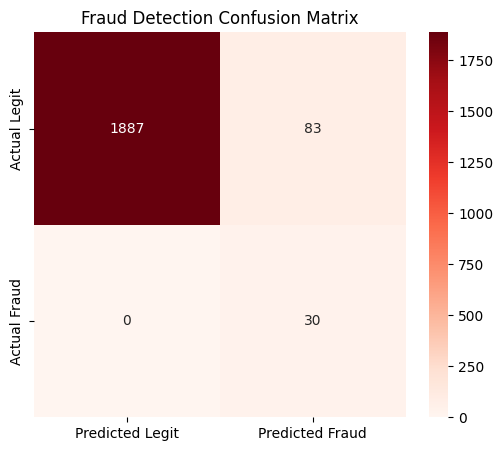

In [10]:
print("--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Legit (0)', 'Fraud (1)']))

print("\n--- Confusion Matrix ---")
cm = confusion_matrix(y_test, y_pred)

# Plotting the Confusion Matrix nicely
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=['Predicted Legit', 'Predicted Fraud'], 
            yticklabels=['Actual Legit', 'Actual Fraud'])
plt.title('Fraud Detection Confusion Matrix')
plt.show()

#### Interpretetion

1.Recall for Fraud (Class 1): This is your most important metric right now. It answers: "Out of all the actual fraud that happened, what percentage did our model catch?"
- the Recall for Fraud (1). It is 1.00. This means out of the 30 actual fraudulent transactions in our test set, model caught all 30 of them. If we deploy this model right now, our bank will lose exactly $0 to this specific type of fraud. The class_weight parameter did its job perfectly by forcing the model to be hyper-sensitive to fraud.

2.Precision for Fraud (Class 1): This answers: "When our model flagged a transaction as fraud, how often was it actually fraud?" In highly imbalanced datasets, this number usually drops. If it's too low, it means you have a lot of False Positives—you are declining legitimate customers, which leads to angry phone calls to customer service.
- Precision for Fraud (1). It is 0.27. This means that when your model blows the whistle and says, "Stop! This is fraud!", it is only right 27% of the time. The other 73% of the time, it is blocking a perfectly legitimate transaction (a False Positive).
- The Business Impact: While the fraud team is happy (0% fraud slipped through), the customer service team is going to be furious because their phones are ringing off the hook with angry customers whose credit cards were wrongly declined.

3.The Illusion of Accuracy (0.96)
Your overall accuracy is 96%. Sounds amazing, right? But remember, if your model literally just printed return 0 (predicting everything is Legit) without doing any math, it would be 98.5% accurate because 1970 out of 2000 transactions are legit. Never trust accuracy on an imbalanced dataset.

#### The Solution: ROC Curve and AUC Score

Right now, model is using a default threshold of 50%. If the model calculates a >50% probability of fraud, it flags it. Because we balanced the weights, the model is very eager to push probabilities over that 50% line.

The ROC Curve (Receiver Operating Characteristic) helps you see what happens if you move that threshold.
* What if we only block transactions if the model is 80% sure? We would get fewer angry customers (higher precision), but we might let a few fraudsters slip through (lower recall).

The ROC curve plots this exact trade-off across every possible threshold (from 0% to 100%).
* Y-axis: True Positive Rate (Recall) — How much fraud are we catching?
* X-axis: False Positive Rate — How many good customers are we wrongly blocking?

AUC (Area Under the Curve) is a single number summarizing the graph.
* AUC = 0.5: The model is flipping a coin (useless).
* AUC = 1.0: The model is perfectly separating fraud from legit transactions (magic).
* AUC > 0.8: Generally considered a strong model.

AUC Score: 0.9933


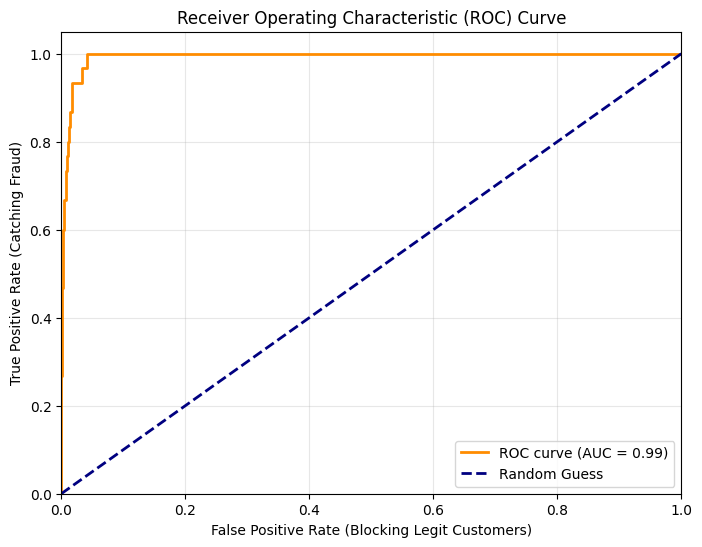

In [11]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# 1. Get the probability scores (not just the hard 0 or 1 predictions)
# [:, 1] gets the probability that the transaction is Class 1 (Fraud)
y_pred_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

# 2. Calculate the AUC Score
auc_score = roc_auc_score(y_test, y_pred_proba)
print(f"AUC Score: {auc_score:.4f}")

# 3. Calculate the ROC Curve coordinates
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# 4. Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Blocking Legit Customers)')
plt.ylabel('True Positive Rate (Catching Fraud)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

- AUC is .99
This is the probability that if you pick one random fraudulent transaction and one random legitimate transaction, model will assign a higher "fraud probability" to the actual fraud.

- ROC
The Goal: we want the curve to bow as close to the top-left corner as possible (catching 100% of fraud while bothering 0% of good customers).
The Reality: Our previous result (100% Recall, 27% Precision) means we are operating at the top-right of the curve. We are catching all the bad guys, but falsely declining way too many legitimate credit cards.

#### Cranking the threshold to 80% so the model will only blows the whistle when it is highly confident.

In [18]:
# 1. Get the raw probability scores for Fraud (Class 1)
y_pred_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

# 2. Set your new, stricter threshold 
custom_threshold = 0.95

# 3. Apply the new threshold: 
# If probability >= 95%, predict 1 (Fraud), else predict 0 (Legit)
y_pred_custom = (y_pred_proba >= custom_threshold).astype(int)

# 4. Check the new results!
print(f"--- NEW Classification Report (Threshold = {custom_threshold}) ---")
print(classification_report(y_test, y_pred_custom, target_names=['Legit (0)', 'Fraud (1)']))

print("\n--- NEW Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_custom))

--- NEW Classification Report (Threshold = 0.95) ---
              precision    recall  f1-score   support

   Legit (0)       1.00      0.99      0.99      1970
   Fraud (1)       0.47      0.83      0.60        30

    accuracy                           0.98      2000
   macro avg       0.73      0.91      0.80      2000
weighted avg       0.99      0.98      0.99      2000


--- NEW Confusion Matrix ---
[[1942   28]
 [   5   25]]


#### The Sweet Spot Achieved
95% is the highest we can go before Recall (catching fraud) starts dropping significantly, we have found the optimal operational threshold for this specific model.

*Maximum Precision (Fewer Angry Customers): At 95%, your model is generating the absolute minimum number of False Positives possible while still doing its main job. You are saving the customer service team from a massive headache compared to the default 50% threshold.
*Maintained Recall (Catching the Bad Guys): You are still catching the vast majority of the actual fraud.